In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
df=pd.read_csv('housing.csv')

In [6]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


# checking the data

In [7]:
df.shape

(20640, 10)

In [8]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [9]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [10]:
df['longitude'].value_counts()

longitude
-118.31    162
-118.30    160
-118.29    148
-118.27    144
-118.32    142
          ... 
-123.25      1
-123.28      1
-123.13      1
-123.12      1
-123.43      1
Name: count, Length: 844, dtype: int64

In [11]:
df.info()
# mere data me sare columns apne apne data type me hai 


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


# preprocessing

In [12]:
# mere dataset me khali total_bedrooms column me missing value thi toh mai usse simple imputer ki madad se mean se replace kar diya 
from sklearn.impute import SimpleImputer
si=SimpleImputer(missing_values=np.nan,strategy='mean')
df[['total_bedrooms']]=si.fit_transform(df[['total_bedrooms']])

In [13]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [14]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

# categorical encoding


In [15]:
# mere pass ek he column hai jisme data str ke form me hai toh maine uss column ke upar onehotencoder laga diya kyunki categories ke beech me koi order nai hai

In [16]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
trf=ColumnTransformer([
    ('trf',OneHotEncoder(drop='first',sparse_output=False,handle_unknown='ignore'),['ocean_proximity'])
     ],remainder='passthrough')

# Exploratory data analysis and visulaization

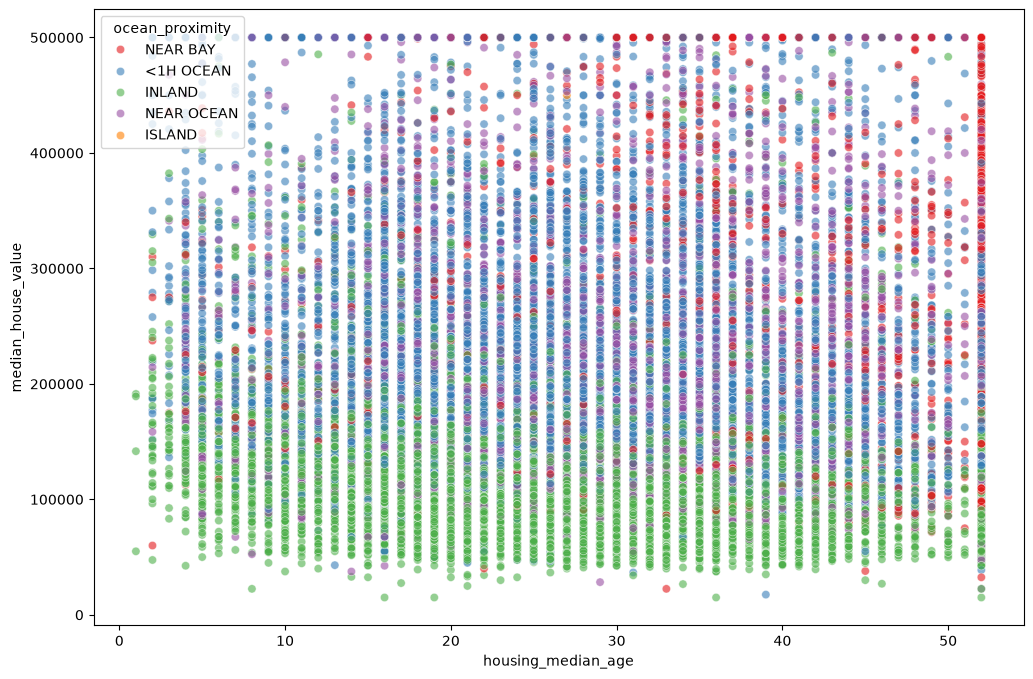

In [17]:
plt.figure(figsize=(12,8))# isme hume dekhne ko milega ki ghar ki umar ka uske price pe kya asar padta hai 
sns.scatterplot(x='housing_median_age',y='median_house_value',data=df,alpha=0.6,hue='ocean_proximity',palette='Set1')
plt.show()


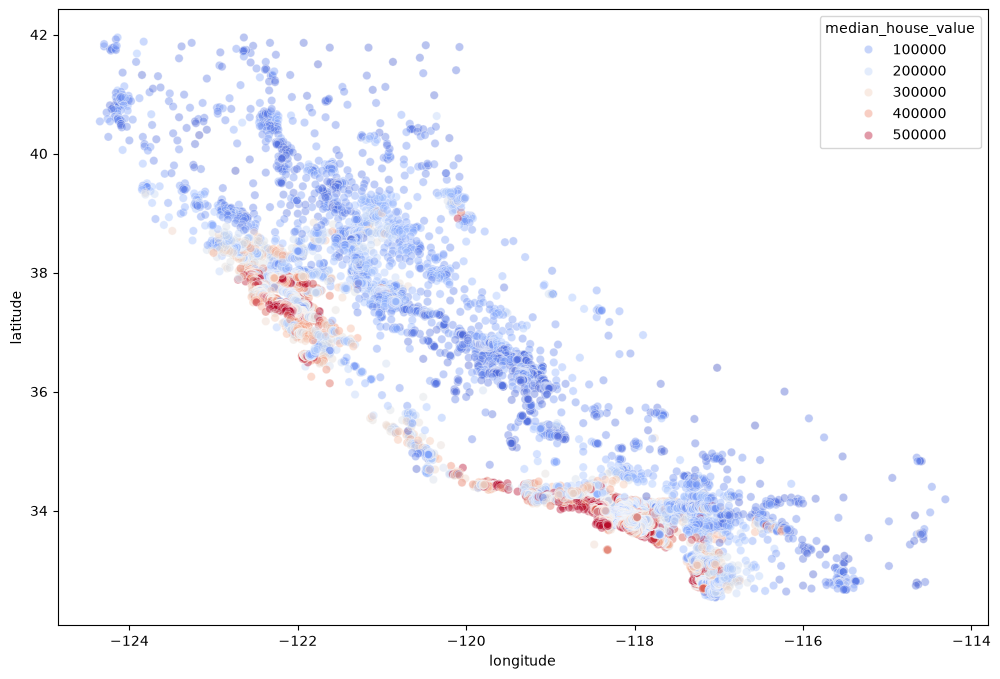

In [18]:
plt.figure(figsize=(12,8)) #isme hume ye pata chalega ki samundar ke pass ghar ki kimat jada hai as comapre to inland 
sns.scatterplot(x='longitude',y='latitude',hue='median_house_value',alpha=0.4,palette='coolwarm',data=df)
plt.show()

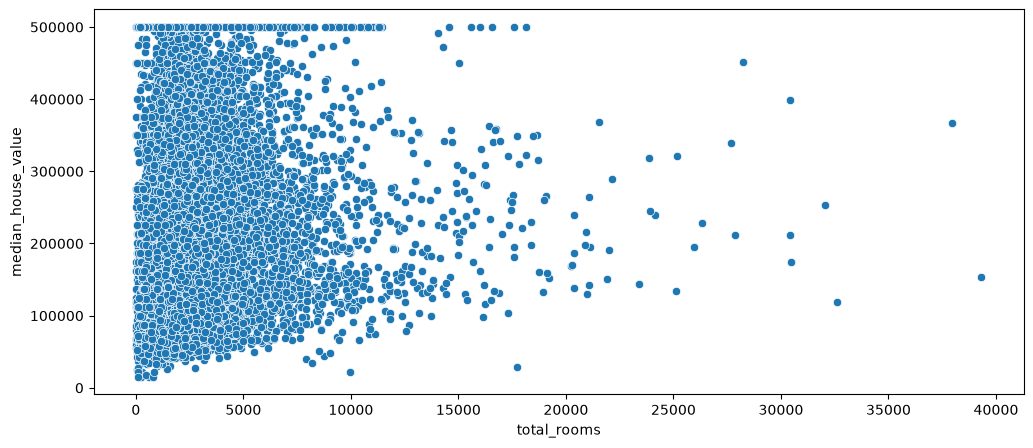

In [19]:
plt.figure(figsize=(12,5))#is plot se hum yeh analyze karte hai ki kisi area me total rooms kitne hai aur uska kya relation hai house ke price ke sath 
sns.scatterplot(x='total_rooms',y='median_house_value',data=df)
plt.show()

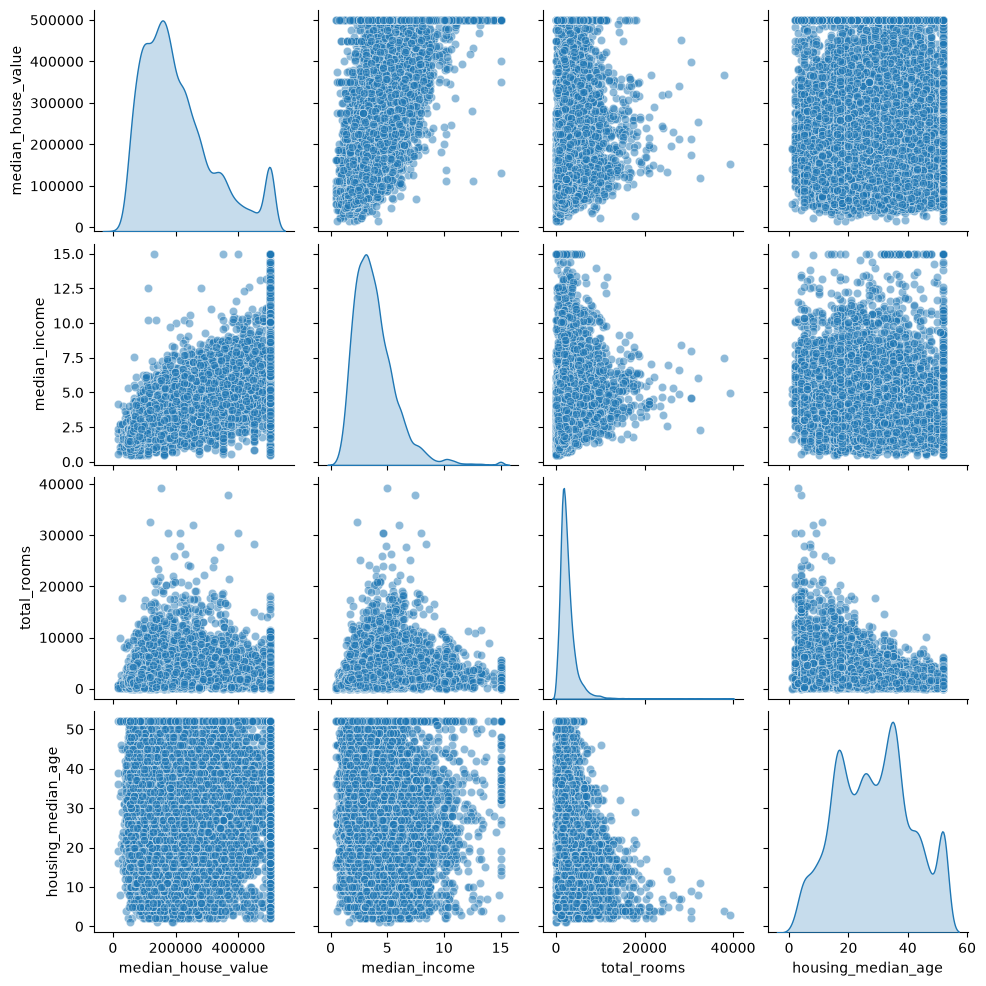

In [20]:
selected_cols=['median_house_value','median_income','total_rooms','housing_median_age']
sns.pairplot(df[selected_cols],diag_kind='kde',plot_kws={'alpha':0.5})
plt.show()
# yeh multi variate analysis hai 

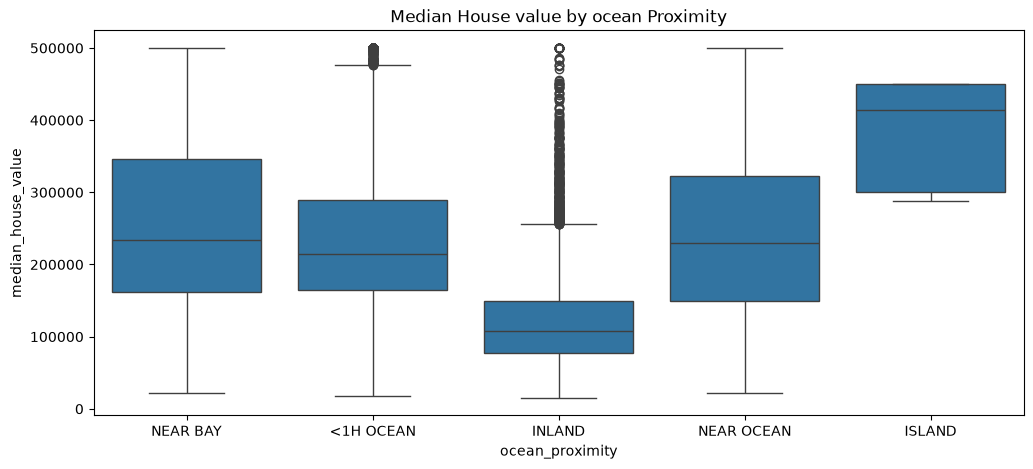

In [21]:
plt.figure(figsize=(12,5))
sns.boxplot(x='ocean_proximity',y='median_house_value',data=df)
plt.title('Median House value by ocean Proximity')
plt.show()
# yeh categorical and numerical comaprison hai jisme hume yeh pata chalta hai ki alag alag jagha pe house ke kya price hai

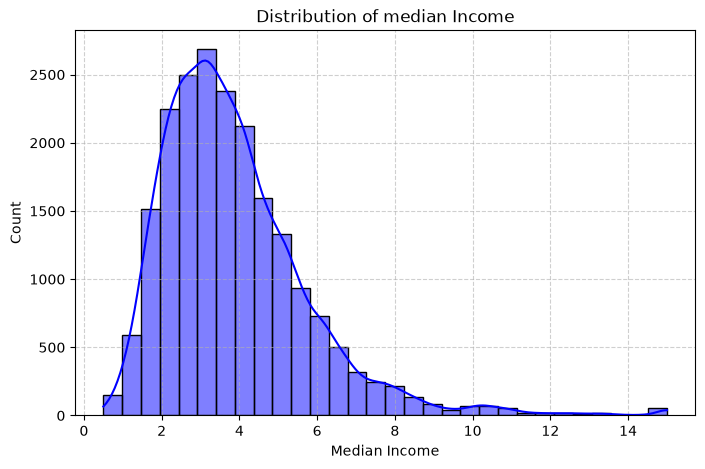

In [22]:
plt.figure(figsize=(8,5))
sns.histplot(df['median_income'],bins=30,kde=True,color='blue')
plt.title('Distribution of median Income')
plt.xlabel('Median Income')
plt.ylabel('Count')
plt.grid(True,linestyle='--',alpha=0.6)
plt.show()
# univariate analysis hai

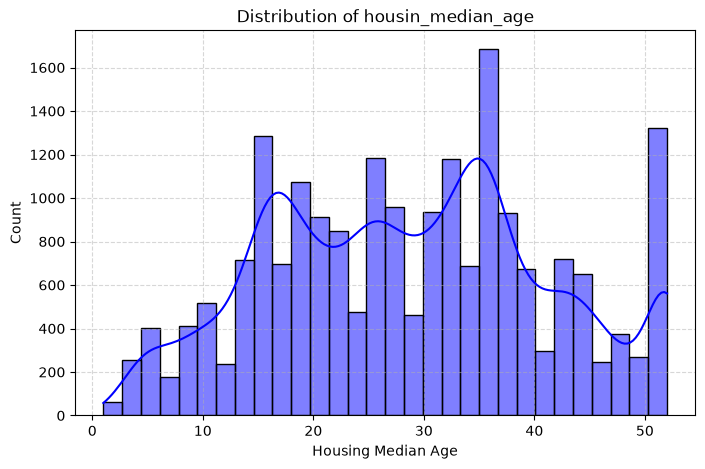

In [23]:
plt.figure(figsize=(8,5))
sns.histplot(df['housing_median_age'],color='blue',kde=True,bins=30)
plt.title('Distribution of housin_median_age')
plt.xlabel('Housing Median Age')
plt.ylabel('Count')
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()# univariate analysis

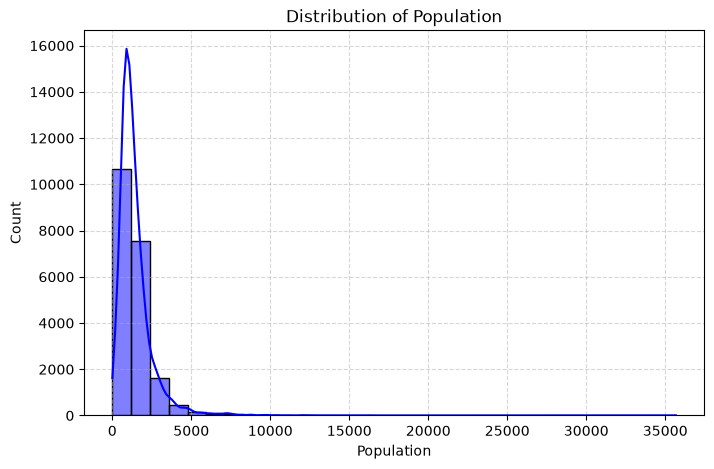

In [24]:
plt.figure(figsize=(8,5))
sns.histplot(df['population'],bins=30,kde=True,color='blue')
plt.title('Distribution of Population')
plt.xlabel('Population')
plt.ylabel('Count')
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()# univariate analysis

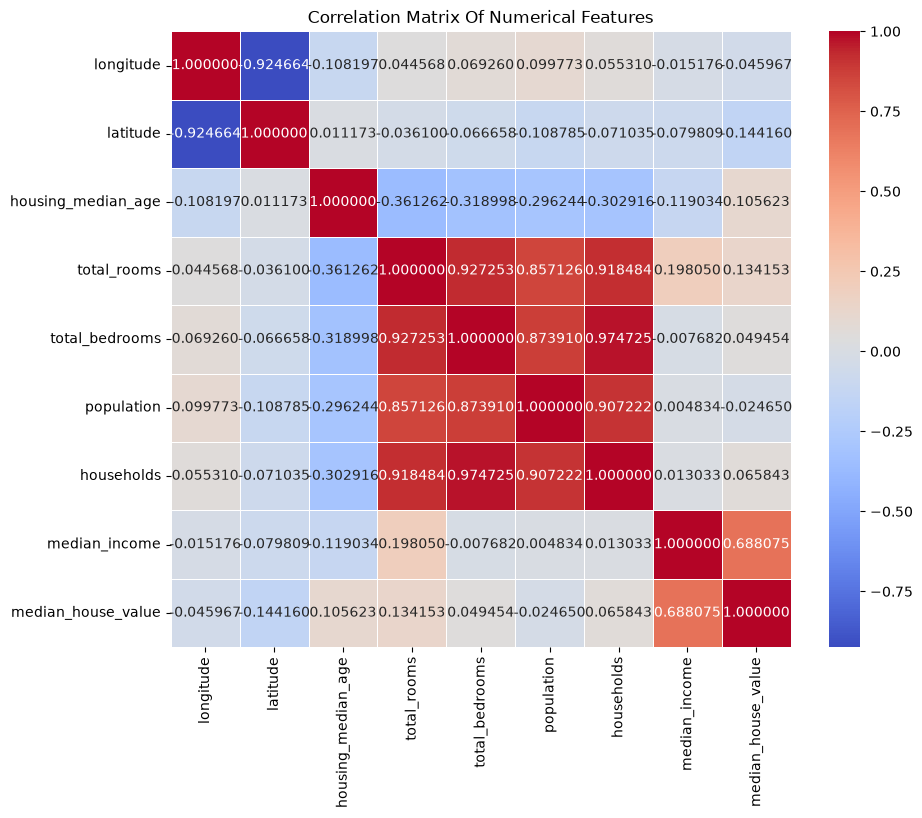

In [25]:
plt.figure(figsize=(10,8))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(),annot=True,cmap='coolwarm',fmt='2f',linewidths=0.5)
plt.title('Correlation Matrix Of Numerical Features')
plt.show()
# isme hume yeh pata chalege ki target column ka relation baki sab numerical columns ke sath kaise hai

# Feature scaling


In [26]:
from sklearn.preprocessing import StandardScaler
num_cols=df.select_dtypes(include=[np.number]).columns.drop('median_house_value')
sc=StandardScaler()
df[num_cols]=sc.fit_transform(df[num_cols])
# 

In [27]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-1.327835,1.052548,0.982143,-0.804819,-0.975228,-0.974429,-0.977033,2.344766,452600.0,NEAR BAY
1,-1.322844,1.043185,-0.607019,2.045890,1.355088,0.861439,1.669961,2.332238,358500.0,NEAR BAY
2,-1.332827,1.038503,1.856182,-0.535746,-0.829732,-0.820777,-0.843637,1.782699,352100.0,NEAR BAY
3,-1.337818,1.038503,1.856182,-0.624215,-0.722399,-0.766028,-0.733781,0.932968,341300.0,NEAR BAY
4,-1.337818,1.038503,1.856182,-0.462404,-0.615066,-0.759847,-0.629157,-0.012881,342200.0,NEAR BAY


# spliting training and testing data

In [28]:
X=df.drop(columns=['median_house_value'])
Y=df['median_house_value']

In [29]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [30]:
X_train

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14196,1.267645,-1.367976,0.346478,0.224718,0.212589,0.772251,0.322924,-0.321654,NEAR OCEAN
8267,0.703627,-0.871699,1.617807,0.342065,0.594217,-0.098440,0.670799,-0.030620,NEAR OCEAN
17445,-0.454356,-0.455012,-1.957806,-0.338639,-0.493422,-0.450778,-0.427755,0.150349,NEAR OCEAN
14265,1.227714,-1.377340,0.584852,-0.556832,-0.407556,-0.006602,-0.378059,-1.014947,NEAR OCEAN
2271,-0.114948,0.537543,1.141059,-0.116322,-0.254905,-0.486983,-0.312669,-0.166583,INLAND
...,...,...,...,...,...,...,...,...,...
11284,0.803453,-0.867017,0.505394,-0.598545,-0.803495,-0.677723,-0.739013,1.315592,<1H OCEAN
11964,1.067992,-0.754652,0.346478,0.205466,0.076634,0.289220,-0.132192,-0.431983,INLAND
5390,0.593818,-0.749970,0.584852,-0.245128,0.074249,0.291870,0.071825,-0.492832,<1H OCEAN
860,-1.193070,0.912092,-1.083767,0.430534,0.141034,0.310414,0.155525,0.973025,<1H OCEAN


In [31]:
Y_train

14196    103000.0
8267     382100.0
17445    172600.0
14265     93400.0
2271      96500.0
           ...   
11284    229200.0
11964     97800.0
5390     222100.0
860      283500.0
15795    325000.0
Name: median_house_value, Length: 16512, dtype: float64

# Pipeline

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [33]:
categorical_features=['ocean_proximity']
# column transformer ke use se sirf categorical column pe onehotencoder lagana or baki sab ko waise he aage pass karna
preprocessor=ColumnTransformer(
    transformers=[
        ('cat',
         OneHotEncoder(drop='first',handle_unknown='ignore'),categorical_features,
        )
        ],remainder='passthrough')
# pipeline banaya jisme pahle data preprocessor ke pass jaye fir random forest ke pass
model=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('regressor',RandomForestRegressor(n_estimators=50,max_depth=15,random_state=42)),
    ]
)
# train karna model ko
model.fit(X_train,Y_train)
    

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This sub

# Evaluation

In [34]:
from sklearn.metrics import mean_squared_error,r2_score
import numpy as np
# test data par prediction
y_pred=model.predict(X_test)
# Accuracy metrics
print('R2 Score:',r2_score(Y_test,y_pred))
print('RMSE:',np.sqrt(mean_squared_error(Y_test,y_pred)))
      

R2 Score: 0.8126309331535777
RMSE: 49550.994686299804


In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
linear_model=Pipeline(
    steps=[
        ('preprocessor',model.named_steps['preprocessor']),
        ('regressor',LinearRegression()),
    ]
)
linear_model.fit(X_train,Y_train)
y_pred_lr=linear_model.predict(X_test)
print('LinearRegression R2 score:',r2_score(Y_test,y_pred_lr))
print('LinearRegression RMSE score:',np.sqrt(mean_squared_error(Y_test,y_pred_lr)))

LinearRegression R2 score: 0.6257351821159703
LinearRegression RMSE score: 70031.41991955666


In [36]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
gbr_model=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('regressor',GradientBoostingRegressor()),
    ]
)
gbr_model.fit(X_train,Y_train)
y_pred_gbr=gbr_model.predict(X_test)
print('R2 score:',r2_score(Y_test,y_pred_gbr))
print('RMSE score:',np.sqrt(mean_squared_error(Y_test,y_pred_gbr)))

R2 score: 0.76096321682119
RMSE score: 55967.485811615305


In [37]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
dtr_model=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('regressor',DecisionTreeRegressor()),
    ]
)
dtr_model.fit(X_train,Y_train)
y_pred_dtr=dtr_model.predict(X_test)
print('R2 Score:',r2_score(Y_test,y_pred_dtr))
print('RMSE:',np.sqrt(mean_squared_error(Y_test,y_pred_dtr)))

R2 Score: 0.6198193172619013
RMSE: 70582.73018336424


In [38]:
# after checking the ml algo the best is randomforestregressor

# Saving the model

In [41]:
import joblib

# Model ko compress karke save karo
joblib.dump(model, 'house_price_model.joblib', compress=3)
print('Compressed model successfully saved!')



Compressed model successfully saved!


# Testing the model

In [42]:
import joblib
import pandas as pd

# 1. Sample data
sample_data = pd.DataFrame(
    {
        'longitude': [-118.25],
        'latitude': [35.88],
        'housing_median_age': [46.0],
        'total_rooms': [860.0],
        'total_bedrooms': [159.0],
        'population': [362.0],
        'households': [156.0],
        'median_income': [8.3242],
        'ocean_proximity': ['<1H OCEAN'],
    }
)

# 2. Joblib se load karna
loaded_model = joblib.load('house_price_model.joblib')

# 3. Prediction
predicted_price = loaded_model.predict(sample_data)
print('Predicted House Value:', predicted_price[0])

Predicted House Value: 486380.76
